# Baseline

This notebook creates a valid submission and evaluates the same baseline on the labeled training set.

In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.io import wavfile

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

In [3]:
import os
print(os.getcwd())
print(os.listdir('.'))

/Users/ecaterina/Developer/pregatire-ML/nitro/random
['__pycache__', 'baseline.ipynb', '.ipynb_checkpoints', 'data', 'mesaje-ascunse.ipynb', 'sample_submission.csv']


In [4]:
from pathlib import Path
import re
import pandas as pd

DATA = Path('data')
train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')
print('train:', train.shape, 'test:', test.shape)

train: (150, 4) test: (13000, 3)


In [5]:
def loadwav(path):
    sr, x = wavfile.read('data/' + path)
    x = (x.astype(np.float32) - 128) / 128
    return sr, x

# data exploration

In [6]:
print(train.head())
print(test.head())
print(train['SubtaskID'].value_counts())

      DatapointID  SubtaskID                  recording_path answer
0  train_s1_00001          1  audio/train/train_s1_00001.wav      J
1  train_s1_00016          1  audio/train/train_s1_00016.wav      N
2     train_00024          2     audio/train/train_00024.wav  PINKY
3  train_s1_00047          1  audio/train/train_s1_00047.wav      D
4     train_00034          2     audio/train/train_00034.wav  FIXES
     DatapointID  SubtaskID                recording_path
0  test_s1_00052          1  audio/test/test_s1_00052.wav
1     test_08015          2     audio/test/test_08015.wav
2     test_02037          2     audio/test/test_02037.wav
3     test_00250          2     audio/test/test_00250.wav
4     test_04204          2     audio/test/test_04204.wav
SubtaskID
1    100
2     50
Name: count, dtype: int64


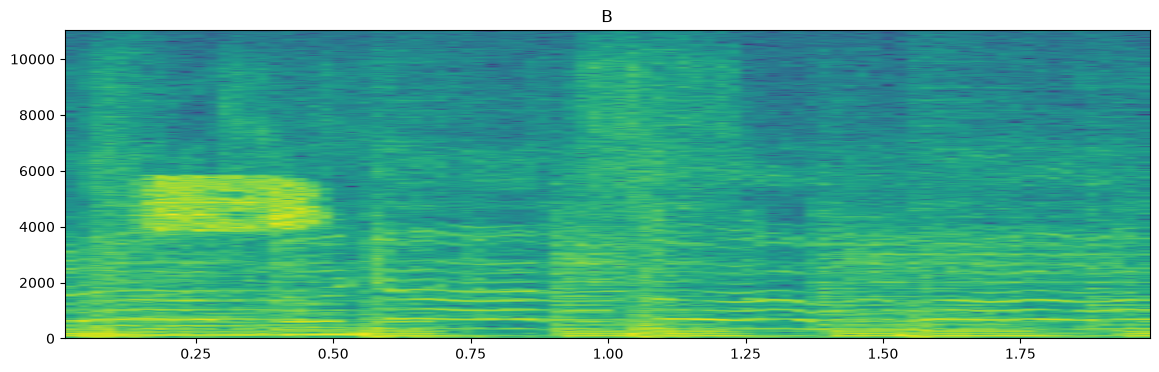

In [7]:
i = 20
sr, x = loadwav(train['recording_path'][i])
plt.figure(figsize=(14, 4))
plt.specgram(x, NFFT=1024, Fs=sr, noverlap=512)
plt.title(train['answer'][i])
plt.show()

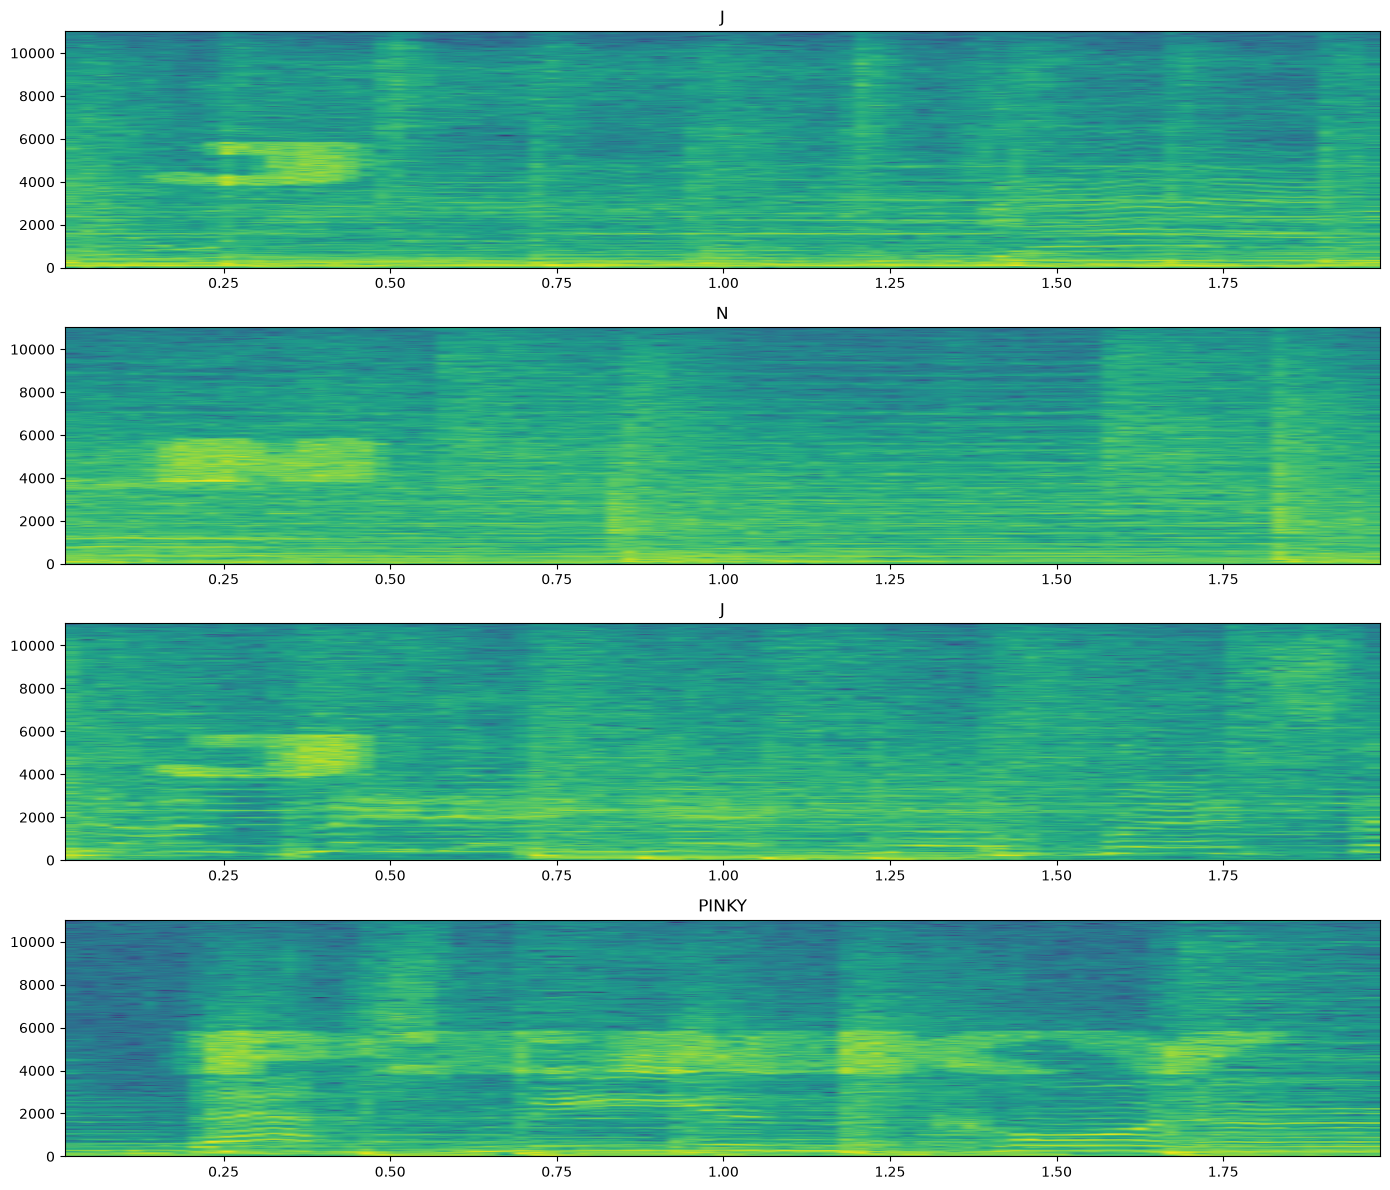

In [8]:
picks = []
count_j = 0
found_n = False
for i in range(len(train)):
    a = train['answer'][i]
    p = train['recording_path'][i]
    if a == 'J' and count_j < 2:
        picks.append((a, p))
        count_j += 1
    if a == 'N' and not found_n:
        picks.append((a, p))
        found_n = True
picks.append((train['answer'][2], train['recording_path'][2]))    # the word PINKY

plt.figure(figsize=(14, 12))
for k in range(len(picks)):
    sr, x = loadwav(picks[k][1])
    plt.subplot(len(picks), 1, k + 1)
    plt.specgram(x, NFFT=1024, Fs=sr, noverlap=512)
    plt.title(picks[k][0])
plt.tight_layout()
plt.show()

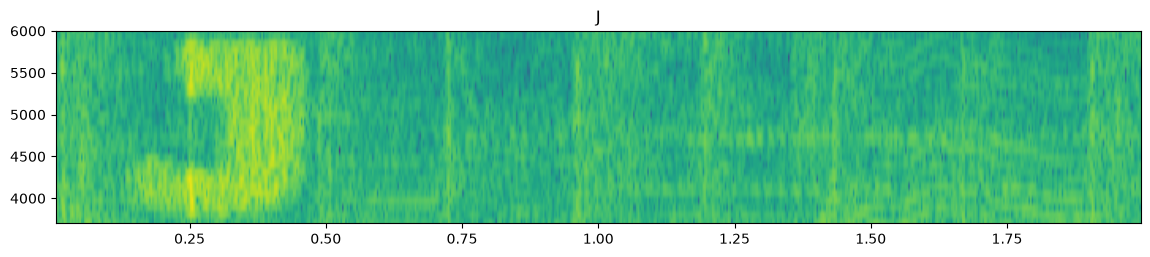

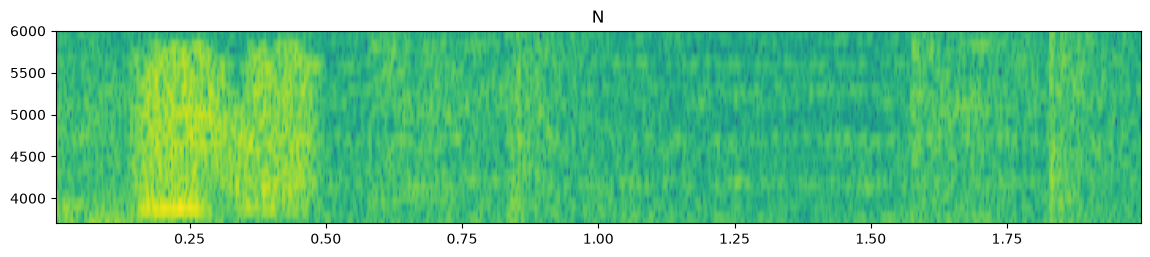

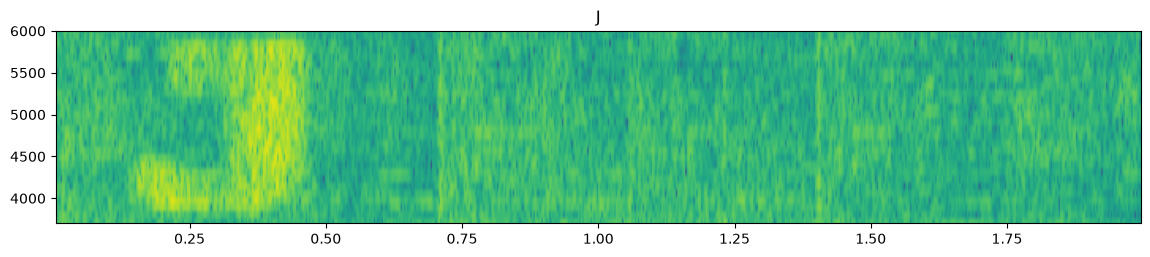

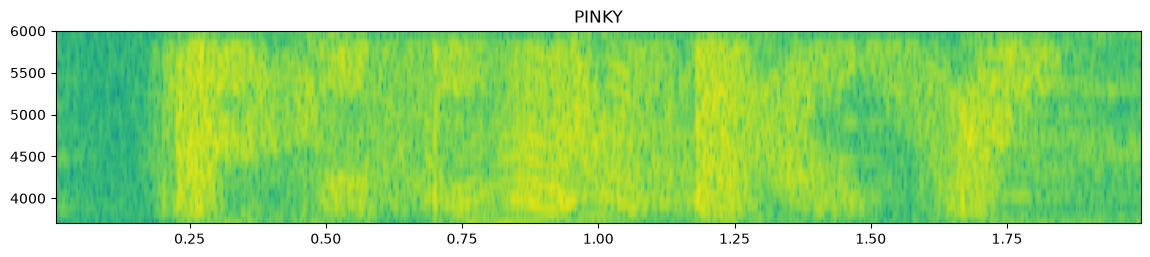

In [9]:
for k in range(len(picks)):
    sr, x = loadwav(picks[k][1])
    plt.figure(figsize=(14, 2.5))
    plt.specgram(x, NFFT=256, Fs=sr, noverlap=192)
    plt.ylim(3700, 6000)        
    plt.title(picks[k][0])
    plt.show()

# more data exploration

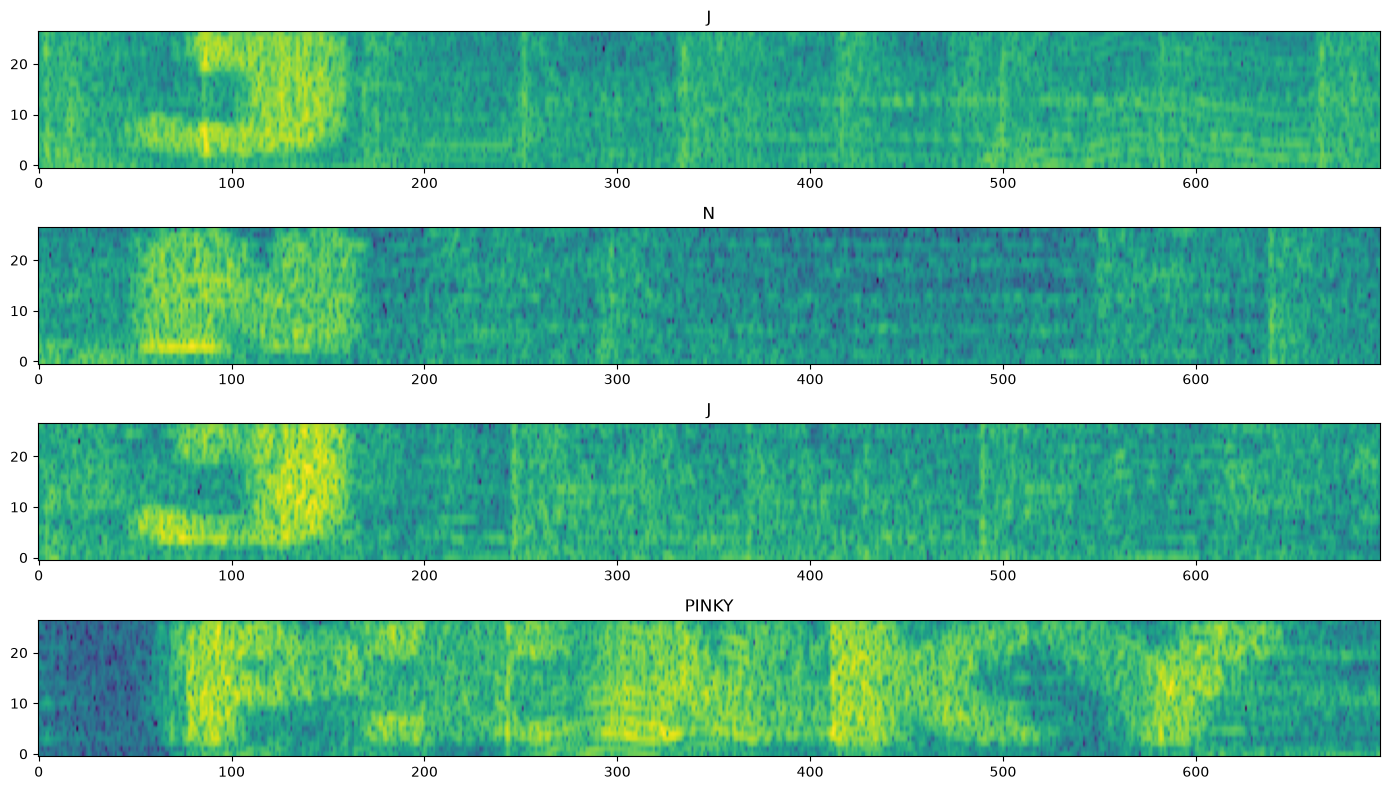

In [10]:
N_FFT = 256
HOP = 63
window = np.hanning(N_FFT)
R0 = int(3700 * N_FFT / sr)
R1 = int(6000 * N_FFT / sr)

def bandspec(x):
    nfr = 1 + (len(x) - N_FFT) // HOP
    S = np.zeros((N_FFT // 2 + 1, nfr))
    for t in range(nfr):
        fr = x[t*HOP : t*HOP + N_FFT] * window
        S[:, t] = np.abs(np.fft.rfft(fr))
    return np.log(S[R0:R1] + 1e-6)

plt.figure(figsize=(14, 8))
for k in range(len(picks)):
    sr, x = loadwav(picks[k][1])
    plt.subplot(len(picks), 1, k + 1)
    plt.imshow(bandspec(x), aspect='auto', origin='lower')
    plt.title(picks[k][0])
plt.tight_layout()
plt.show()

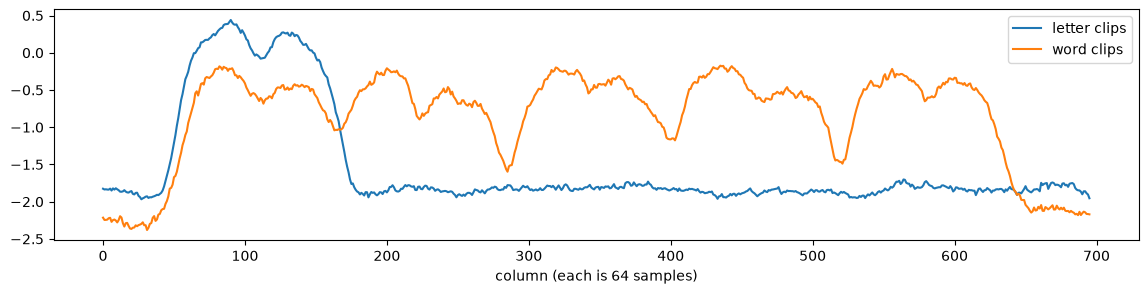

In [11]:
sumsub1 = 0
nr1 = 0
sumsub2 = 0
nr2 = 0
for i in range(len(train)):
    sr, x = loadwav(train['recording_path'][i])
    B = bandspec(x)
    if train['SubtaskID'][i] == 1:
        sumsub1 += B
        nr1 += 1
    else:
        sumsub2 += B
        nr2 += 1

plt.figure(figsize=(14, 3))
plt.plot((sumsub1 / nr1).mean(axis=0), label='letter clips')
plt.plot((sumsub2 / nr2).mean(axis=0), label='word clips')
plt.legend()
plt.xlabel('column (each is 64 samples)')
plt.show()

# model + preparing for the model + validation


In [12]:
C0 = 40 #unde incepe litera
W = 120
LETTERS = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'

def cutouts(x):
    B = bandspec(x)
    out = np.zeros((5, B.shape[0], W))
    for k in range(5):
        c = B[:, C0 + k*W : C0 + (k+1)*W]
        out[k] = (c - c.mean()) / (c.std() + 1e-6)
    return out

In [13]:
train_cut = []
for i in range(len(train)):
    sr, x = loadwav(train['recording_path'][i])
    train_cut.append(cutouts(x))
train_cut = np.array(train_cut)          
print(train_cut.shape)

(150, 5, 27, 120)


In [14]:
words = pd.read_csv(DATA / 'word_list.csv')
wordstr = list(words['answer'].astype(str).str.upper())
wordidx = np.zeros((len(wordstr), 5), dtype=int)
for w in range(len(wordstr)):
    for k in range(5):
        wordidx[w, k] = LETTERS.index(wordstr[w][k])

def lettexpl(rows):
    X = []
    y = []
    for i in rows:
        ans = train['answer'][i]
        for k in range(len(ans)):
            X.append(train_cut[i, k].reshape(-1))
            y.append(ans[k])
    return np.array(X), np.array(y)

def predword(cut, subtask, model):
    probs = model.predict_proba(cut.reshape(5, -1))
    if subtask == 1:
        return LETTERS[probs[0].argmax()]
    scores = np.ones(len(wordstr))
    for k in range(5):
        scores = scores * probs[k][wordidx[:, k]]
    return wordstr[scores.argmax()]
    

In [15]:
def eval(model):
    scores = []
    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    for fit_rows, val_rows in kf.split(train, train['SubtaskID']):
        X_fit, y_fit = lettexpl(fit_rows)
        model.fit(X_fit, y_fit)

        letrue = []
        lepred = []
        wtrue = []
        wpred = []
        for i in val_rows:
            pred = predword(train_cut[i], train['SubtaskID'][i], model)
            if train['SubtaskID'][i] == 1:
                letrue.append(train['answer'][i])
                lepred.append(pred)
            else:
                wtrue.append(train['answer'][i])
                wpred.append(pred)

    sclet = accuracy(letrue, lepred)     
    scw = evaluate(wtrue, wpred)           
    scores.append(0.25 * sclet + 0.75 * scw)

    print('folds:', [round(s, 3) for s in scores])
    print('mean:', round(np.mean(scores), 4), ' spread:', round(np.std(scores), 4))
    return scores

In [16]:
### din baseline

def normalize(value):
    return re.sub('[^A-Z]', '', str(value).upper())

def levenshtein(a, b):
    previous = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        current = [i]
        for j, cb in enumerate(b, 1):
            current.append(min(previous[j] + 1, current[j - 1] + 1, previous[j - 1] + (ca != cb)))
        previous = current
    return previous[-1]

    
def evaluate(truth, predictions):
    scores = []
    for expected, predicted in zip(truth, predictions):
        expected = normalize(expected)
        predicted = normalize(predicted)
        distance = levenshtein(expected, predicted)
        similarity = max(0, 1 - distance / max(len(expected), len(predicted), 1))
        scores.append(0.5 * similarity + 0.5 * (expected == predicted))
    return 100 * sum(scores) / len(scores)

def accuracy(truth, predictions):
    correct = 0
    for expected, predicted in zip(truth, predictions):
        correct += normalize(expected) == normalize(predicted)
    return 100 * correct / len(truth)

In [17]:
rez = {}
for C in [0.1, 1, 10, 100]:
  model = LogisticRegression(C=C, max_iter=2000)
  scores = eval(model)
  rez[C] = np.mean(scores)

best = None
for val in rez:
  if best is None or rez[val] > rez[best]:
    best = val
print('best C:', best, round(rez[best], 4))

folds: [91.75]
mean: 91.75  spread: 0.0
folds: [93.0]
mean: 93.0  spread: 0.0
folds: [94.25]
mean: 94.25  spread: 0.0
folds: [94.25]
mean: 94.25  spread: 0.0
best C: 10 94.25


## Predictions

Replace this constant prediction with your solution. Subtask 1 expects one letter; subtask 2 expects a five-letter word.

In [18]:
## final
X, y = lettexpl(range(len(train)))
model = LogisticRegression(C=best, max_iter=2000)
model.fit(X, y)

preds = []
for i in range(len(test)):
  sr, x = loadwav(test['recording_path'][i])
  preds.append(predword(cutouts(x), test['SubtaskID'][i], model))

submission = pd.DataFrame({'DatapointID': test['DatapointID'], 'SubtaskID': test['SubtaskID'], 'answer': preds})
submission.to_csv('submission.csv', index=False)
submission.head()

,DatapointID,SubtaskID,answer
0,test_s1_00052,1,I
1,test_08015,2,KOURA
2,test_02037,2,DUMPY
3,test_00250,2,BHANG
4,test_04204,2,SAMBO
